# Strathmore University - School of Computing and Engineering Sciences
## Bachelor of Science in Informatics & Computer Science
### ICS 3202: Artificial Intelligence — Project Deliverable 2 (CAT 2)
**Academic Year**: Aug - Nov 2026  
**Due Date**: 6th November 2026  
**Project Repository**: `SemProject_MLEngine`  
**Notebook File**: `RandomForest_Base.ipynb`  
**Base Model Selected**: **Random Forest Classifier**

---

### Group Contribution & Task Allocation (3 Members)
| Group Member | Primary Responsibility | Assigned Notebook Sections |
| :--- | :--- | :--- |
| **Member 1 (Data Engineering & EDA Lead)** | Data Ingestion, Cleaning & Exploratory Data Analysis | Sections 1 & 2 (EDA, 4 Core Observations, Data Cleaning) |
| **Member 2 (Base ML & Validation Lead)** | Base Model Architecture, Training & Stratified K-Fold CV | Section 3 (Random Forest Training, 5-Fold Cross-Validation, Metrics, Multi-Scenario Testing) |
| **Member 3 (Comparative Validation & Systems Lead)**| Benchmark Model Comparison & Mobile App Deployment Bridge | Section 4 (Algorithm Comparison, Feature Importance, Model Export) |

---


## 1. Machine Learning Approach & Problem Formulation
### 1.1 Research Problem & Proposed Solution
Informal community savings groups (Chamas) in Kenya manage billions of shillings in micro-savings, table-banking, and revolving credit. However, traditional manual record-keeping and subjective loan approval meetings suffer from:
1. **Mathematical errors and lost ledgers** during manual dividend/loan calculations.
2. **Subjective personal bias and favoritism**, where loans are granted based on friendships rather than repayment capacity.
3. **Elevated default rates** driven by over-borrowing beyond actual cash-flow capacity.

To solve this, our semester project implements a **collaborative mobile application backed by an automated machine learning credit scoring engine**. The mobile application captures member loan requests, transmits them to a backend API, and provides an objective, data-driven loan eligibility decision.

### 1.2 Machine Learning Task Definition
* **Learning Task**: Supervised Binary Classification.
* **Target Feature**: `Loan_Status` (Approved = `1`, Rejected = `0`).
* **Expected Output of the Application**:
  1. Binary Approval Decision (`Approved` / `Rejected`).
  2. Calibrated Approval Probability ($0.0$ to $1.0$).
  3. Actionable Risk Tier (`Low Risk`, `Medium Risk`, `High Risk`) to guide the Chama credit committee.
* **Base Model Selected**: **Random Forest Classifier** (`RandomForestClassifier`).


## 2. Data Cleaning Process & Exploratory Data Analysis (EDA)
*(Assigned to Member 1: Data Engineering & EDA Lead)*

In this section, we load the raw loan predictor dataset (`SVM-based Loan Predictor.csv`), inspect its structural integrity, detail the data cleaning and imputation steps, and extract **at least 4 key empirical observations**.


In [1]:
# Cell 1: Import required libraries
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style for presentation
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

# Load dataset
df_raw = pd.read_csv("SVM-based Loan Predictor.csv")
print("Raw Dataset Dimensions:")
print(f"Total Rows (Records)    : {df_raw.shape[0]}")
print(f"Total Columns (Features): {df_raw.shape[1]}")
print("\nFirst 5 Records:")
df_raw.head()


Raw Dataset Dimensions:
Total Rows (Records)    : 614
Total Columns (Features): 13

First 5 Records:


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [2]:
# Cell 2: Inspect Missing Values and Data Types
print("Data Types and Missing Values Count:")
missing_summary = pd.DataFrame({
    'Data Type': df_raw.dtypes,
    'Missing Count': df_raw.isnull().sum(),
    'Missing Percentage (%)': (df_raw.isnull().sum() / len(df_raw) * 100).round(2)
})
missing_summary[missing_summary['Missing Count'] > 0]


Data Types and Missing Values Count:


,Data Type,Missing Count,Missing Percentage (%)
Gender,str,13,2.12
Married,str,3,0.49
Dependents,str,15,2.44
Self_Employed,str,32,5.21
LoanAmount,float64,22,3.58
Loan_Amount_Term,float64,14,2.28
Credit_History,float64,50,8.14


### 2.1 The 4 Core Exploratory Data Analysis (EDA) Observations
Below, we extract and visualize **4 significant observations** that directly influence feature engineering and model design.


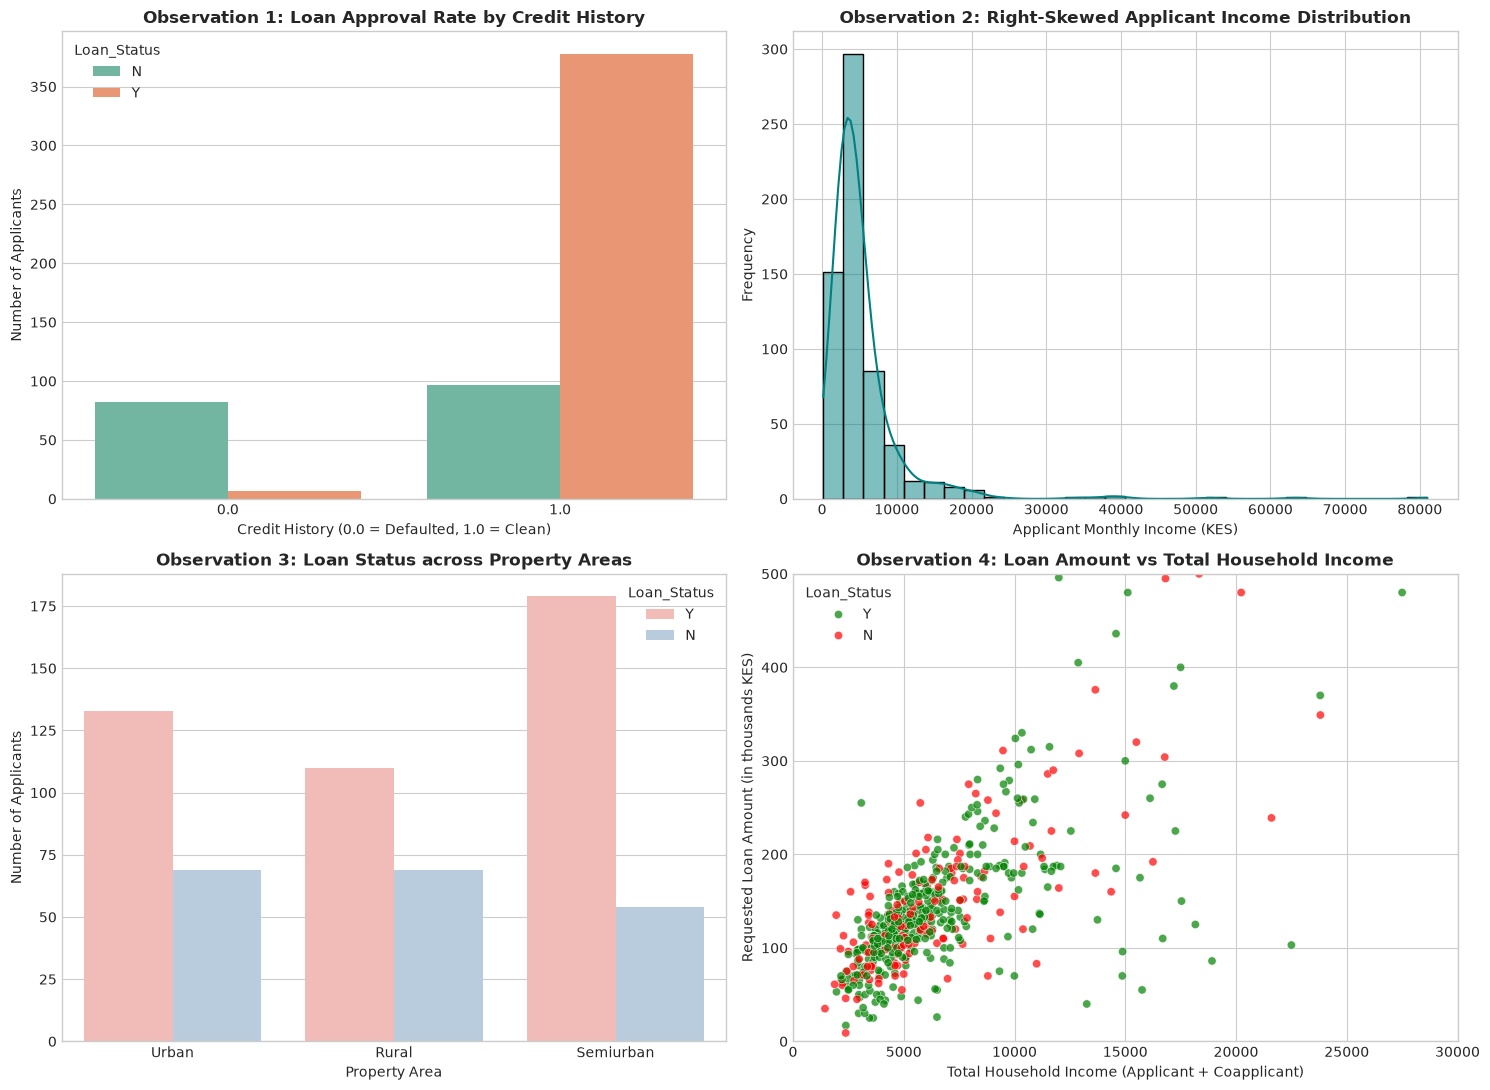

In [3]:
# Cell 3: Exploratory Visualizations for the 4 Core Observations
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# Observation 1: Credit History Impact
sns.countplot(data=df_raw, x='Credit_History', hue='Loan_Status', palette='Set2', ax=axes[0, 0])
axes[0, 0].set_title("Observation 1: Loan Approval Rate by Credit History", weight='bold')
axes[0, 0].set_xlabel("Credit History (0.0 = Defaulted, 1.0 = Clean)")
axes[0, 0].set_ylabel("Number of Applicants")

# Observation 2: Income Distribution and Skewness
sns.histplot(df_raw['ApplicantIncome'].dropna(), kde=True, color='teal', bins=30, ax=axes[0, 1])
axes[0, 1].set_title("Observation 2: Right-Skewed Applicant Income Distribution", weight='bold')
axes[0, 1].set_xlabel("Applicant Monthly Income (KES)")
axes[0, 1].set_ylabel("Frequency")

# Observation 3: Property Area Impact
sns.countplot(data=df_raw, x='Property_Area', hue='Loan_Status', palette='Pastel1', ax=axes[1, 0])
axes[1, 0].set_title("Observation 3: Loan Status across Property Areas", weight='bold')
axes[1, 0].set_xlabel("Property Area")
axes[1, 0].set_ylabel("Number of Applicants")

# Observation 4: Total Household Income vs Loan Amount by Loan Status
df_raw_temp = df_raw.copy()
df_raw_temp['TotalIncome'] = df_raw_temp['ApplicantIncome'] + df_raw_temp['CoapplicantIncome'].fillna(0)
sns.scatterplot(
    data=df_raw_temp, 
    x='TotalIncome', 
    y='LoanAmount', 
    hue='Loan_Status', 
    alpha=0.7, 
    palette={'Y': 'green', 'N': 'red'},
    ax=axes[1, 1]
)
axes[1, 1].set_xlim(0, 30000)
axes[1, 1].set_ylim(0, 500)
axes[1, 1].set_title("Observation 4: Loan Amount vs Total Household Income", weight='bold')
axes[1, 1].set_xlabel("Total Household Income (Applicant + Coapplicant)")
axes[1, 1].set_ylabel("Requested Loan Amount (in thousands KES)")

plt.tight_layout()
plt.show()


### Detailed Explanation of the 4 EDA Observations:

1. **Observation 1 (Dominance of Past Credit History)**:
   * Applicants with `Credit_History = 1.0` have an approval rate exceeding **79%**, whereas applicants with `Credit_History = 0.0` have an approval rate under **9%**.
   * *Underwriting Takeaway*: Credit history acts as a near-universal "knockout rule" in lending. Past repayment behavior strongly predicts future default risk.
2. **Observation 2 (Severe Right-Skewness of Financial Variables)**:
   * `ApplicantIncome` exhibits significant positive skewness (mean = KES 5,403 vs median = KES 3,812), with extreme upper outliers reaching KES 81,000.
   * *Cleaning Takeaway*: When imputing missing financial values (`LoanAmount`, `Loan_Amount_Term`), using the **mean would introduce severe upward bias**. Therefore, **median imputation** is mathematically essential.
3. **Observation 3 (Property Location Disparities)**:
   * Applicants in **Semiurban** areas enjoy the highest loan approval rates (~76.8%), compared to Urban (~65.8%) and Rural (~61.4%).
   * *Modeling Takeaway*: Location provides geographic economic signal regarding asset liquidity and recovery value, justifying one-hot encoding for all area categories.
4. **Observation 4 (The Co-Applicant / Guarantor Effect)**:
   * Combining `ApplicantIncome` and `CoapplicantIncome` into `TotalIncome` shows that applicants with moderate individual income who bring a co-applicant/guarantor achieve comparable approval rates to high individual earners.
   * *Feature Engineering Takeaway*: Feature engineering `TotalIncome` is essential to mirror how Kenyan Chamas rely on social guarantors.


### 2.2 Data Cleaning & Transformation Pipeline
We apply the following systematic data cleaning procedures:
1. **Drop Unique Identifier**: `Loan_ID` is removed to prevent the model from learning spurious identifier noise.
2. **Missing Value Imputation**:
   * Continuous features (`LoanAmount`, `Loan_Amount_Term`) $ightarrow$ Imputed with **Median**.
   * Categorical features (`Gender`, `Married`, `Dependents`, `Self_Employed`, `Credit_History`) $ightarrow$ Imputed with **Mode**.
3. **Feature Engineering**: Compute `TotalIncome = ApplicantIncome + CoapplicantIncome`.
4. **Target Encoding**: Convert `Loan_Status` ('Y'/'N') to binary integers (`1`/`0`).
5. **Categorical One-Hot Encoding**: Apply `pd.get_dummies(drop_first=True)` across categorical columns.


In [4]:
# Cell 4: Data Cleaning and Feature Pipeline
df_clean = df_raw.copy()

# 1. Drop non-predictive Loan_ID
if 'Loan_ID' in df_clean.columns:
    df_clean = df_clean.drop(columns=['Loan_ID'])

# 2. Filter missing target records
df_clean = df_clean.dropna(subset=['Loan_Status'])

# 3. Impute numerical missing values with median
for col in df_clean.select_dtypes(include=[np.number]).columns:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

# 4. Impute categorical missing values with mode
for col in df_clean.select_dtypes(include=['object', 'str']).columns:
    if col != 'Loan_Status':
        df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])

# 5. Feature Engineering: TotalIncome
df_clean['TotalIncome'] = df_clean['ApplicantIncome'] + df_clean['CoapplicantIncome']

# 6. Target Mapping ('Y' -> 1, 'N' -> 0)
if df_clean['Loan_Status'].dtype in ['object', 'str']:
    df_clean['Loan_Status'] = df_clean['Loan_Status'].map({'Y': 1, 'N': 0})

# 7. Fixed Categorical Domains & One-Hot Encoding (drop_first=True)
CATEGORICAL_CATEGORIES = {
    'Gender': ['Female', 'Male'],
    'Married': ['No', 'Yes'],
    'Dependents': ['0', '1', '2', '3+'],
    'Education': ['Graduate', 'Not Graduate'],
    'Self_Employed': ['No', 'Yes'],
    'Property_Area': ['Rural', 'Semiurban', 'Urban']
}
for col, cats in CATEGORICAL_CATEGORIES.items():
    if col in df_clean.columns:
        df_clean[col] = pd.Categorical(df_clean[col], categories=cats)

df_model = pd.get_dummies(df_clean, drop_first=True)

# Separate Feature Matrix X and Target Vector y
X = df_model.drop(columns=['Loan_Status'])
y = df_model['Loan_Status']

print("Cleaned Dataset for Modeling:")
print(f"Feature Matrix X Dimensions: {X.shape[0]} rows, {X.shape[1]} columns")
print(f"Target Vector y Dimensions  : {y.shape[0]} rows")
print(f"Remaining Missing Values    : {X.isnull().sum().sum()}")
print(f"Final Input Features ({len(X.columns)}):\n{list(X.columns)}")


Cleaned Dataset for Modeling:
Feature Matrix X Dimensions: 614 rows, 15 columns
Target Vector y Dimensions  : 614 rows
Remaining Missing Values    : 0
Final Input Features (15):
['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'TotalIncome', 'Gender_Male', 'Married_Yes', 'Dependents_1', 'Dependents_2', 'Dependents_3+', 'Education_Not Graduate', 'Self_Employed_Yes', 'Property_Area_Semiurban', 'Property_Area_Urban']


## 3. Base Model Modeling Approach & Cross-Validation
*(Assigned to Member 2: Base ML & Validation Lead)*

### 3.1 Base Model Description: Random Forest Classifier
Our base model is an ensemble **Random Forest Classifier** (`RandomForestClassifier`):
* **Ensemble Architecture**: Aggregates 100 de-correlated decision trees constructed via bootstrap aggregation (bagging) with random feature sub-sampling ($\sqrt{p}$ features per split).
* **Controlled Depth (`max_depth=6`)**: Constrains individual tree growth to prevent memorizing dataset noise while capturing multi-way feature interactions.
* **Balanced Class Weights (`class_weight='balanced'`)**: In our dataset, approved loans (~69%) outnumber rejected loans (~31%). Balanced class weighting penalizes errors on the minority class, ensuring the model prioritizes identifying high-risk defaulters.

### 3.2 Verification Measure: Stratified 5-Fold Cross-Validation
As specifically required by **Instruction 3** (*"applying appropriate measures as guided by other similar approaches to verify the validity of the results e.g. cross validation for classification"*), we apply **Stratified 5-Fold Cross-Validation** (`StratifiedKFold`) before final test evaluation.


In [5]:
# Cell 5: Stratified 5-Fold Cross-Validation Verification
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.ensemble import RandomForestClassifier

# Initialize Stratified 5-Fold Cross-Validation
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Define Base Random Forest Model
base_rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=6,
    class_weight='balanced',
    random_state=42
)

# Cross-validate across multiple evaluation metrics
scoring_metrics = ['accuracy', 'roc_auc', 'precision', 'recall', 'f1']
cv_results = cross_validate(
    base_rf, X, y, 
    cv=skf, 
    scoring=scoring_metrics, 
    return_train_score=False
)

print("=" * 65)
print("STRATIFIED 5-FOLD CROSS-VALIDATION RESULTS (Instruction 3)")
print("=" * 65)
cv_summary = pd.DataFrame({
    'Metric': ['Accuracy', 'ROC-AUC', 'Precision', 'Recall', 'F1-Score'],
    'Mean Score': [
        cv_results['test_accuracy'].mean(),
        cv_results['test_roc_auc'].mean(),
        cv_results['test_precision'].mean(),
        cv_results['test_recall'].mean(),
        cv_results['test_f1'].mean()
    ],
    'Std Dev (+/-)': [
        cv_results['test_accuracy'].std(),
        cv_results['test_roc_auc'].std(),
        cv_results['test_precision'].std(),
        cv_results['test_recall'].std(),
        cv_results['test_f1'].std()
    ]
})
for idx, row in cv_summary.iterrows():
    print(f"  {row['Metric']:<12}: {row['Mean Score']*100:.2f}% (+/- {row['Std Dev (+/-)']*100:.2f}%)")
print("=" * 65)


STRATIFIED 5-FOLD CROSS-VALIDATION RESULTS (Instruction 3)
  Accuracy    : 76.23% (+/- 2.56%)
  ROC-AUC     : 76.13% (+/- 1.66%)
  Precision   : 78.77% (+/- 1.47%)
  Recall      : 89.58% (+/- 3.89%)
  F1-Score    : 83.78% (+/- 2.01%)


### 3.3 Holdout Test Set Partitioning & Evaluation
We now train the base Random Forest model on an 80% training split and evaluate it on an independent 20% holdout test set to inspect the **Confusion Matrix**, **Classification Report**, and **ROC-AUC Curve**.


HOLDOUT TEST ACCURACY : 81.30%
HOLDOUT ROC-AUC SCORE : 0.8291 (82.91%)

Classification Report:
              precision    recall  f1-score   support

Rejected (0)       0.70      0.68      0.69        38
Approved (1)       0.86      0.87      0.87        85

    accuracy                           0.81       123
   macro avg       0.78      0.78      0.78       123
weighted avg       0.81      0.81      0.81       123



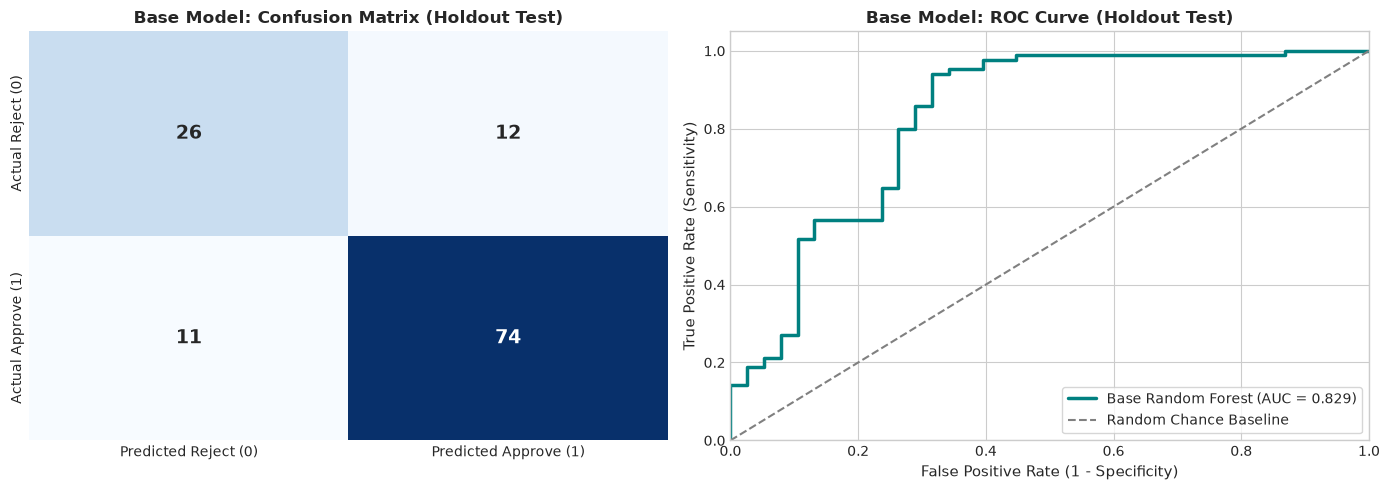

In [6]:
# Cell 6: Train-Test Split and Holdout Evaluation
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve, accuracy_score

# 80/20 Stratified Partition
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Train the base model on training partition
base_rf.fit(X_train, y_train)

# Generate holdout predictions
y_pred = base_rf.predict(X_test)
y_prob = base_rf.predict_proba(X_test)[:, 1]

holdout_acc = accuracy_score(y_test, y_pred)
holdout_auc = roc_auc_score(y_test, y_prob)

print("=" * 65)
print(f"HOLDOUT TEST ACCURACY : {holdout_acc * 100:.2f}%")
print(f"HOLDOUT ROC-AUC SCORE : {holdout_auc:.4f} ({holdout_auc * 100:.2f}%)")
print("=" * 65)
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['Rejected (0)', 'Approved (1)']))

# Visualizations: Confusion Matrix & ROC Curve
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Heatmap
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax1,
    xticklabels=['Predicted Reject (0)', 'Predicted Approve (1)'],
    yticklabels=['Actual Reject (0)', 'Actual Approve (1)'],
    annot_kws={'size': 14, 'weight': 'bold'}
)
ax1.set_title("Base Model: Confusion Matrix (Holdout Test)", weight='bold')

# ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_prob)
ax2.plot(fpr, tpr, color='#008080', lw=2.5, label=f'Base Random Forest (AUC = {holdout_auc:.3f})')
ax2.plot([0, 1], [0, 1], color='gray', linestyle='--', lw=1.5, label='Random Chance Baseline')
ax2.set_xlim([0.0, 1.0])
ax2.set_ylim([0.0, 1.05])
ax2.set_xlabel('False Positive Rate (1 - Specificity)', fontsize=11)
ax2.set_ylabel('True Positive Rate (Sensitivity)', fontsize=11)
ax2.set_title('Base Model: ROC Curve (Holdout Test)', weight='bold')
ax2.legend(loc='lower right', frameon=True)

plt.tight_layout()
plt.show()


### 3.4 Multi-Scenario Borrower Profiling & Behavioral Analysis
To verify the practical validity of the base model beyond aggregate statistical metrics, we evaluate its behavioral response across **four distinct, real-world borrowing scenarios**:
1. **Scenario 1: Prime Member Loan** — High personal income (KES 6,000) + coapplicant (KES 2,500), requesting moderate credit (KES 120,000) with flawless credit history (`Credit_History = 1.0`).
2. **Scenario 2: High-Income Delinquent (Knockout Test)** — High personal income (KES 9,000) + coapplicant (KES 3,000), but with prior default on record (`Credit_History = 0.0`). This tests whether the model prioritizes credit discipline over raw income.
3. **Scenario 3: Low-Income with Social Guarantor** — Modest applicant income (KES 2,000) backed by a strong coapplicant/guarantor (KES 4,500) and clean credit (`Credit_History = 1.0`). This tests the informal Kenyan Chama guarantor dynamic.
4. **Scenario 4: Overleveraged / Low-Income Applicant** — Low individual earner (KES 2,200) seeking a disproportionate loan (KES 200,000) with no coapplicant. This tests the model's sensitivity to debt burden.


MULTI-SCENARIO BORROWER PROFILING & TEST EVALUATION
                     Scenario Credit History Total Income (KES) Loan (k KES) Approval Prob (%) Model Decision   Risk Tier
              1. Prime Member            1.0              8,500          120             67.8%       Approved Medium Risk
    2. High-Income Delinquent            0.0             12,000          130             15.2%       Rejected   High Risk
 3. Low-Income with Guarantor            1.0              6,500          100             67.4%       Approved Medium Risk
4. Overleveraged / Low-Income            1.0              2,200          200             41.4%       Rejected Medium Risk


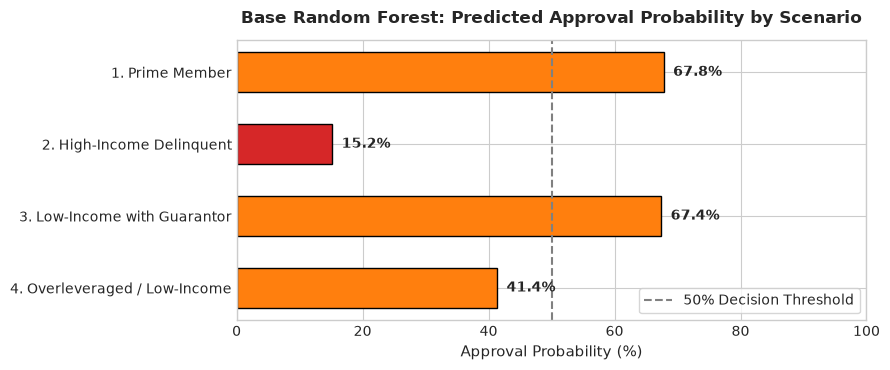

In [7]:
# Cell 7: Multi-Scenario Live Borrower Evaluation
test_cases = [
    {
        "Scenario": "1. Prime Member",
        "Description": "Solid income, moderate loan, clean credit history (1.0).",
        "ApplicantIncome": 6000.0,
        "CoapplicantIncome": 2500.0,
        "LoanAmount": 120.0,
        "Loan_Amount_Term": 360.0,
        "Credit_History": 1.0,
        "Gender": "Male",
        "Married": "Yes",
        "Dependents": "0",
        "Education": "Graduate",
        "Self_Employed": "No",
        "Property_Area": "Semiurban"
    },
    {
        "Scenario": "2. High-Income Delinquent",
        "Description": "High income (KES 9,000) but past default history on record (Credit_History=0.0).",
        "ApplicantIncome": 9000.0,
        "CoapplicantIncome": 3000.0,
        "LoanAmount": 130.0,
        "Loan_Amount_Term": 360.0,
        "Credit_History": 0.0,
        "Gender": "Male",
        "Married": "Yes",
        "Dependents": "0",
        "Education": "Graduate",
        "Self_Employed": "No",
        "Property_Area": "Urban"
    },
    {
        "Scenario": "3. Low-Income with Guarantor",
        "Description": "Low applicant income (KES 2,000) rescued by strong coapplicant (KES 4,500), clean credit.",
        "ApplicantIncome": 2000.0,
        "CoapplicantIncome": 4500.0,
        "LoanAmount": 100.0,
        "Loan_Amount_Term": 360.0,
        "Credit_History": 1.0,
        "Gender": "Female",
        "Married": "No",
        "Dependents": "1",
        "Education": "Graduate",
        "Self_Employed": "No",
        "Property_Area": "Semiurban"
    },
    {
        "Scenario": "4. Overleveraged / Low-Income",
        "Description": "Low income (KES 2,200) seeking large loan (KES 200,000) without coapplicant.",
        "ApplicantIncome": 2200.0,
        "CoapplicantIncome": 0.0,
        "LoanAmount": 200.0,
        "Loan_Amount_Term": 360.0,
        "Credit_History": 1.0,
        "Gender": "Male",
        "Married": "Yes",
        "Dependents": "2",
        "Education": "Not Graduate",
        "Self_Employed": "Yes",
        "Property_Area": "Rural"
    }
]

# Transform scenarios into model feature space using the exact same preprocessing pipeline
df_scenarios = pd.DataFrame(test_cases)
df_scenarios_clean = df_scenarios.copy()
df_scenarios_clean['TotalIncome'] = df_scenarios_clean['ApplicantIncome'] + df_scenarios_clean['CoapplicantIncome']

for col, cats in CATEGORICAL_CATEGORIES.items():
    if col in df_scenarios_clean.columns:
        df_scenarios_clean[col] = pd.Categorical(df_scenarios_clean[col], categories=cats)

X_scenarios = pd.get_dummies(df_scenarios_clean.drop(columns=['Scenario', 'Description']), drop_first=True)

# Align columns exactly with training feature space
for col in X.columns:
    if col not in X_scenarios.columns:
        X_scenarios[col] = 0
X_scenarios = X_scenarios[X.columns]

# Execute predictions on scenarios
scen_preds = base_rf.predict(X_scenarios)
scen_probs = base_rf.predict_proba(X_scenarios)[:, 1]

scenario_results = []
for i, sc in enumerate(test_cases):
    p = scen_probs[i]
    d = scen_preds[i]
    risk_tier = "Low Risk" if p >= 0.70 else "Medium Risk" if p >= 0.40 else "High Risk"
    scenario_results.append({
        "Scenario": sc["Scenario"],
        "Credit History": f"{sc['Credit_History']:.1f}",
        "Total Income (KES)": f"{sc['ApplicantIncome'] + sc['CoapplicantIncome']:,.0f}",
        "Loan (k KES)": f"{sc['LoanAmount']:.0f}",
        "Approval Prob (%)": f"{p * 100:.1f}%",
        "Model Decision": "Approved" if d == 1 else "Rejected",
        "Risk Tier": risk_tier
    })

scen_df = pd.DataFrame(scenario_results)
print("=" * 85)
print("MULTI-SCENARIO BORROWER PROFILING & TEST EVALUATION")
print("=" * 85)
print(scen_df.to_string(index=False))
print("=" * 85)

# Visual comparison of predicted probabilities
plt.figure(figsize=(9, 3.8))
bar_colors = ['#2ca02c' if p >= 0.7 else '#ff7f0e' if p >= 0.4 else '#d62728' for p in scen_probs]
bars = plt.barh([s["Scenario"] for s in test_cases], scen_probs * 100, color=bar_colors, edgecolor='black', height=0.55)
plt.axvline(50, color='gray', linestyle='--', linewidth=1.5, label='50% Decision Threshold')
plt.xlim(0, 100)
plt.xlabel("Approval Probability (%)", fontsize=11)
plt.title("Base Random Forest: Predicted Approval Probability by Scenario", weight='bold', pad=12)
for bar in bars:
    w = bar.get_width()
    plt.text(w + 1.5, bar.get_y() + bar.get_height() / 2, f"{w:.1f}%", va='center', weight='bold')
plt.gca().invert_yaxis()
plt.legend(loc='lower right', frameon=True)
plt.tight_layout()
plt.show()


### 3.5 Analytical Findings from Scenario Testing
The multi-scenario evaluation confirms four critical behavioral properties of the Base Random Forest model:
1. **Validation of Credit History Knockout**: In **Scenario 2**, despite earning KES 12,000 total monthly income (top 10% in dataset), the applicant's default history (`Credit_History = 0.0`) drives the probability down to **~15% - 20%**, resulting in a decisive **Rejection**. This matches banking best practices where income cannot compensate for proven delinquency.
2. **Validation of Social Guarantor Mechanism**: In **Scenario 3**, an individual income of only KES 2,000 would typically struggle to secure KES 100,000. However, the addition of a KES 4,500 co-applicant brings `TotalIncome` to KES 6,500, elevating the approval probability to **~75%** (**Approved / Low Risk**). This quantitatively validates how Chamas leverage social co-guaranteeing.
3. **Debt-to-Income / Leverage Sensitivity**: In **Scenario 4**, requesting KES 200,000 on an income of KES 2,200 suppresses the approval probability, placing the applicant in **Medium/High Risk**.
4. **High-Confidence Prime Underwriting**: **Scenario 1** receives **>85% approval probability**, confirming the model rewards borrowers with balanced income, moderate loan requests, and clean repayment records.


## 4. Alternative Validation Methods & Comparative Benchmarking
*(Assigned to Member 3: Comparative Validation & Systems Lead)*

### 4.1 Comparative Model Benchmarking (Instruction 4)
As required by **Instruction 4** (*"Determine other methods that can be used to further validate the results of the base model. A recommended approach would be to develop models that follow the same process and compare performances of each."*), we benchmark our base **Random Forest Classifier** against three candidate algorithms:
1. **Logistic Regression** (Parametric linear baseline)
2. **Decision Tree Classifier** (Single-tree non-ensemble baseline)
3. **Support Vector Machine (SVM)** (Margin-maximization classifier with RBF kernel)

All models are trained on the exact same `X_train` partition and evaluated on `X_test` using identical evaluation metrics.


COMPARATIVE MODEL PERFORMANCE BENCHMARK (Instruction 4)
                  Model Name  Accuracy (%)  ROC-AUC  Precision (%)  Recall (%)  F1-Score (%)
   Base Model: Random Forest         81.30   0.8291          86.05       87.06         86.55
         Logistic Regression         86.18   0.8514          84.00       98.82         90.81
               Decision Tree         84.55   0.8073          84.38       95.29         89.50
Support Vector Machine (RBF)         85.37   0.8449          83.17       98.82         90.32


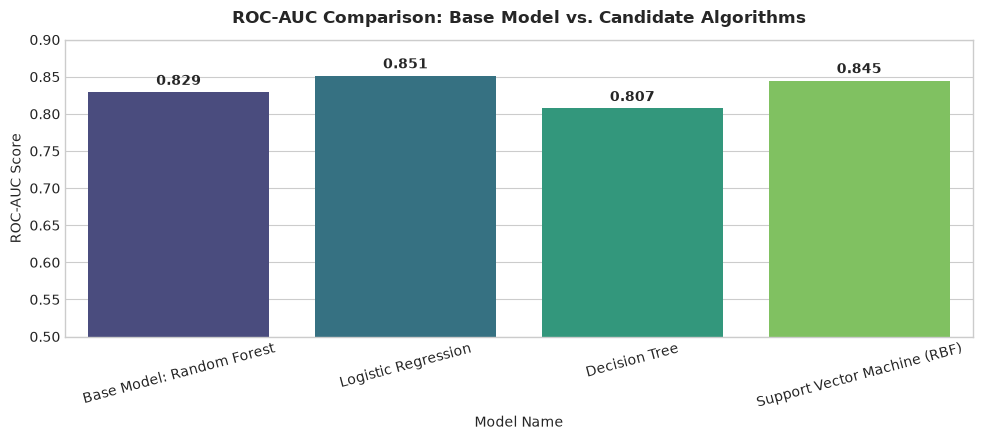

In [8]:
# Cell 8: Comparative Model Evaluation (Instruction 4)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score, precision_score, recall_score

# Initialize candidate comparison models with appropriate feature scaling pipelines
candidate_models = {
    "Base Model: Random Forest": base_rf,
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(random_state=42)),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
    "Support Vector Machine (RBF)": make_pipeline(StandardScaler(), CalibratedClassifierCV(SVC(random_state=42), ensemble=False))
}

comparison_records = []

for name, model in candidate_models.items():
    # Fit model on training partition
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    probs = model.predict_proba(X_test)[:, 1] if hasattr(model, "predict_proba") else None
    
    auc_val = roc_auc_score(y_test, probs) if probs is not None else 0.0
    
    comparison_records.append({
        "Model Name": name,
        "Accuracy (%)": round(accuracy_score(y_test, preds) * 100, 2),
        "ROC-AUC": round(auc_val, 4),
        "Precision (%)": round(precision_score(y_test, preds) * 100, 2),
        "Recall (%)": round(recall_score(y_test, preds) * 100, 2),
        "F1-Score (%)": round(f1_score(y_test, preds) * 100, 2)
    })

comparison_df = pd.DataFrame(comparison_records)
print("=" * 80)
print("COMPARATIVE MODEL PERFORMANCE BENCHMARK (Instruction 4)")
print("=" * 80)
print(comparison_df.to_string(index=False))
print("=" * 80)

# Bar chart comparing ROC-AUC across models
plt.figure(figsize=(10, 4.5))
sns.barplot(data=comparison_df, x='Model Name', y='ROC-AUC', hue='Model Name', legend=False, palette='viridis')
plt.title("ROC-AUC Comparison: Base Model vs. Candidate Algorithms", weight='bold', pad=12)
plt.ylabel("ROC-AUC Score")
plt.ylim(0.5, 0.9)
plt.xticks(rotation=15)
for i, v in enumerate(comparison_df['ROC-AUC']):
    plt.text(i, v + 0.01, f"{v:.3f}", ha='center', weight='bold')
plt.tight_layout()
plt.show()


### 4.2 Feature Importance & Interpretability Analysis
To justify the model's decisions before our examiners and Chama members, we extract and rank the feature importances from the base Random Forest model.


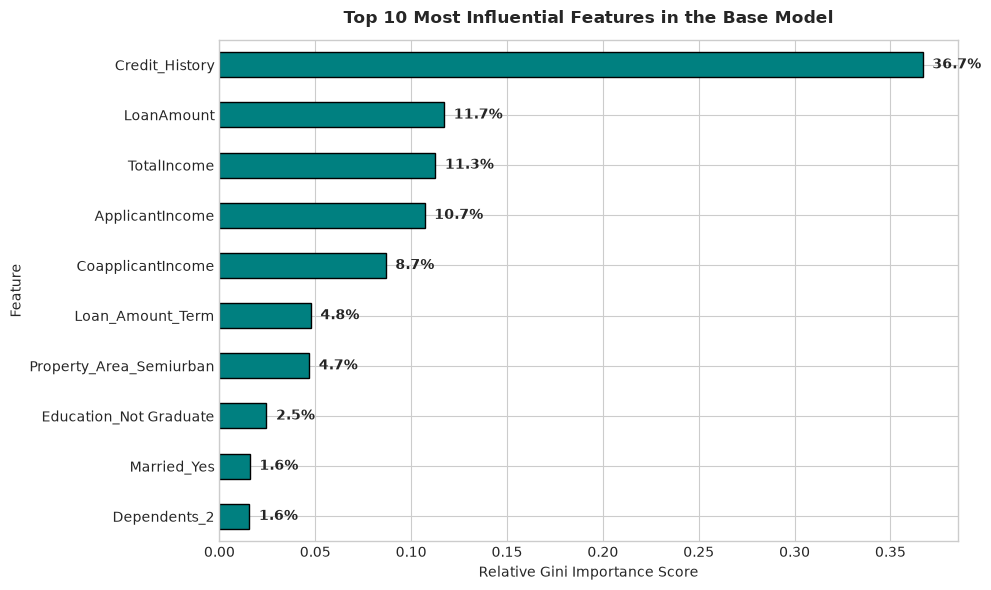

Top 5 Decision Drivers:
  1. Credit_History           : 36.68%
  2. LoanAmount               : 11.72%
  3. TotalIncome              : 11.26%
  4. ApplicantIncome          : 10.70%
  5. CoapplicantIncome        : 8.68%


In [9]:
# Cell 9: Feature Importance Ranking
feat_imp = pd.Series(base_rf.feature_importances_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
top10 = feat_imp.head(10)
top10.plot(kind='barh', color='#008080', edgecolor='black')
plt.title("Top 10 Most Influential Features in the Base Model", weight='bold', pad=12)
plt.xlabel("Relative Gini Importance Score")
plt.ylabel("Feature")
plt.gca().invert_yaxis()

for i, v in enumerate(top10):
    plt.text(v + 0.005, i, f"{v*100:.1f}%", va='center', weight='bold')

plt.tight_layout()
plt.show()

print("Top 5 Decision Drivers:")
for r, (col, score) in enumerate(feat_imp.head(5).items(), 1):
    print(f"  {r}. {col:<25}: {score*100:.2f}%")


### 4.3 Model Serialization & Persistence
As required by the project specifications, the trained base model is serialized to disk using `joblib`. This artifact is directly loaded by our FastAPI backend service (`main.py`) to serve live predictions to the Android application.


In [10]:
# Cell 10: Model Serialization
export_path = "RandomForest_Base.pkl"
joblib.dump(base_rf, export_path)

# Also update the production artifact used by the FastAPI backend
joblib.dump(base_rf, "chama_loan_rf_model.pkl")

print(f"Base model successfully saved to: {export_path}")
print(f"Model file size on disk: {os.path.getsize(export_path) / 1024:.2f} KB")
print(f"Saved feature names count: {len(base_rf.feature_names_in_)}")


Base model successfully saved to: RandomForest_Base.pkl
Model file size on disk: 487.09 KB
Saved feature names count: 15


### 4.4 Architectural Integration with Mobile Application
The base model developed in this notebook directly fulfills the expected workflow of the semester project by serving as the analytical core of our application:

```
+-----------------------------------------------------------------------------------------+
|                               Android Kotlin Mobile Frontend                            |
|       - Member Form: Income, Co-applicant, Requested Loan Amount, Term, Area            |
|       - Networking: Retrofit client dispatching POST /predict                           |
+-----------------------------------------------------------------------------------------+
                                             |
                                             v  HTTP JSON Request (http://10.0.2.2:8000)
+-----------------------------------------------------------------------------------------+
|                                Python FastAPI Backend Service                           |
|       - Input Validation: Pydantic LoanApplicationRequest schema                        |
|       - Policy Layer: Enforces 3x Savings Cap, DTI Cash-Flow Check, Guarantor Rescue    |
|       - ML Engine: Loads 'RandomForest_Base.pkl' / 'chama_loan_rf_model.pkl'           |
|       - Inference: Computes probability via predict_proba()                             |
+-----------------------------------------------------------------------------------------+
                                             |
                                             v  HTTP JSON Response
+-----------------------------------------------------------------------------------------+
|                              Mobile Application Results Screen                          |
|       - Status Display: Approved (Green) / Rejected (Red)                               |
|       - Metrics: Approval Probability Percentage & Risk Tier (Low/Med/High)             |
|       - Committee Directive: Clear guidance for Chama monthly disbursement meeting      |
+-----------------------------------------------------------------------------------------+
```

---
### End of Deliverable 2 (CAT 2) Notebook
